Парная линейная регрессия
Цель работы
    Познакомиться с моделью парной линейной регрессии регрессии и методом градиентного спуска.

Содержание работы
Найти оценки параметров модели парной линейной регрессии прямыми вычислениями и палучить с помощью модели прогнозы результативного прознака.
Найти оценки параметров модели парной линейной регрессии с использованием метода градиентного спуска.
Оценить качество построенной модели, сравнив на графике обучающую выборку и прогнозы.
Построить кривые обучения.

In [1]:
# Загрузим необходимые библиотеки
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = np.array([3, 5, 7, 6, 9])
Y = np.array([3, 7, 11, 14, 15])
display(x, Y)

array([3, 5, 7, 6, 9])

array([ 3,  7, 11, 14, 15])

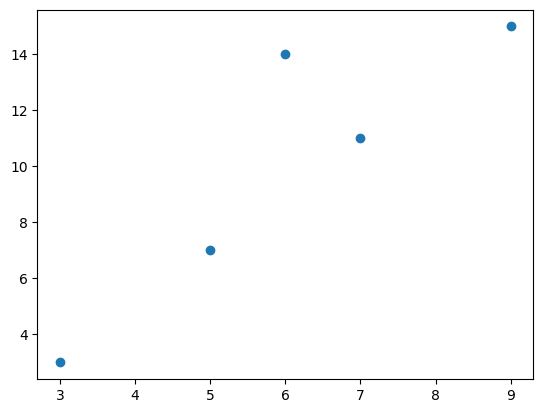

In [3]:
# Изобразим их на графике
plt.figure()
plt.scatter(x, Y)
plt.show()

In [4]:
# Вычислим оценки коэффициентов парной линейной регрессии по формулам
a1 = ((x - x.mean()) * (Y - Y.mean())).mean() / ((x - x.mean()) ** 2).mean()
a0 = Y.mean() - a1 * x.mean()
print("Модель линейной регрессии: Y^ = ", a0, " + ", a1, "* x")

Модель линейной регрессии: Y^ =  -2.0  +  2.0 * x


In [5]:
# Дадим серию прогнозов Y^ для x от 3 до 9 с шагом 1
x_space = np.linspace(3, 9, 7)
print(x_space)
Y_pred = a0 + a1 * x_space
print(Y_pred)

[3. 4. 5. 6. 7. 8. 9.]
[ 4.  6.  8. 10. 12. 14. 16.]


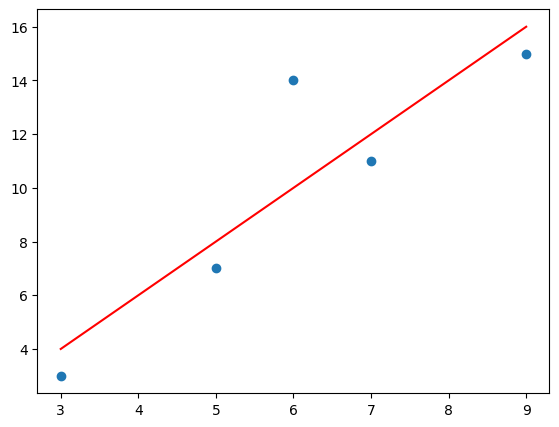

In [6]:
# Изобразим на графике исходные данные и прогнозы
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, "r")
# ax.scatter(x_space, Y_pred)

In [7]:
# Реализуем шаг градиентного спуска в модели парной лдинейной регрессии


class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0

    def predict(self, x):
        return self.a0 + self.a1 * x

    def MSE(self, x, Y):
        return ((self.predict(x) - Y) ** 2).mean()

    def fit(self, x, Y):
        alpha = 0.1
        dT_a0 = -2 * sum((Y - self.predict(x)))
        dT_a1 = -2 * sum((Y - self.predict(x)) * x)
        self.a0 -= alpha * dT_a0
        self.a1 -= alpha * dT_a1

In [8]:
# Получим прогнозы до градиентного спуска с начальными значениями параметров
regr = SimpleRegression()
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print(regr.MSE(x, Y))

0
0
0
0
0
120.0


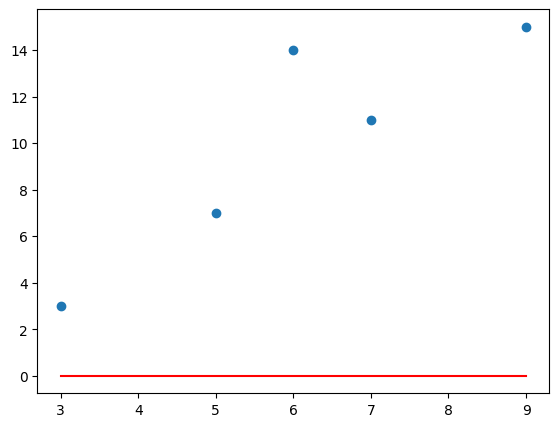

In [9]:
# Выведем прогнозы до градиентного спуска на графике
x_space = np.linspace(3, 9, 7)
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, "r")

MSE после первого шага градиентного спуска:  183892.0


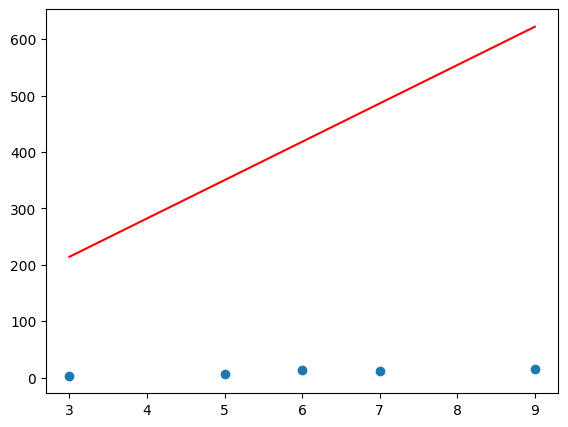

In [10]:
# Реализуем шаг градиентного спуска
regr.fit(x, Y)
print("MSE после первого шага градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, "r")

In [11]:
# Реализуем цикл градиентного спуска


class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0

    def predict(self, x):
        return self.a0 + self.a1 * x

    def MSE(self, x, Y):
        return ((Y - self.predict(x)) ** 2).mean()

    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()

    def MAPE(self, x, Y):
        return abs((Y - self.predict(x)) / Y).mean()

    def fit(self, x, Y, alpha=0.001, epsylon=0.01, max_steps=5000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2 * sum((Y - self.predict(x)))
            dT_a1 = -2 * sum((Y - self.predict(x)) * x)
            self.a0 -= alpha * dT_a0
            self.a1 -= alpha * dT_a1
            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)
            if new_error < epsylon:
                break
        return steps, errors

In [12]:
# Запустим цикл градиентного спуска с заданной точностью 5
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha=0.001, epsylon=5)

5.004697916218
8.190462542210001
11.376227168202002
9.783344855206002
14.561991794194002
MSE после градиентного спуска:  4.709918696051655


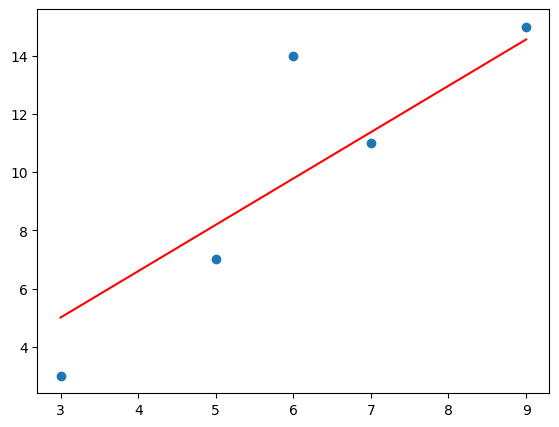

In [13]:
# Выведем график  прогнозов и вычислим MSE
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, "r")

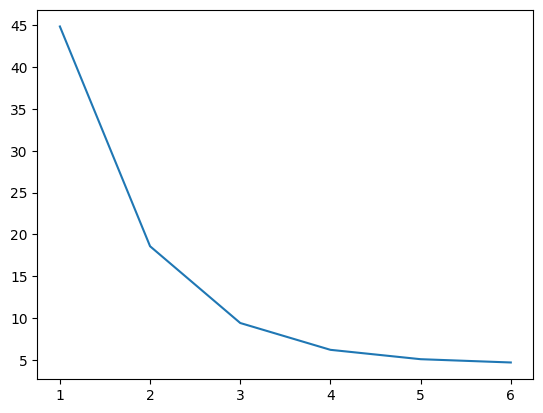

In [14]:
# Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

In [15]:
# Запустим цикл градиентного спуска с заданной точностью 0.05
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha=0.001, epsylon=0.05)

MSE после градиентного спуска:  4.000028517306817


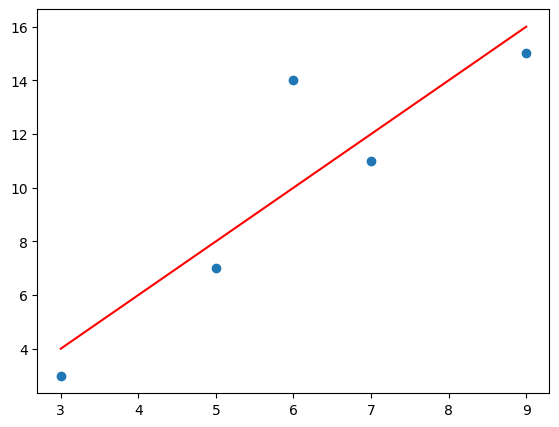

In [16]:
# Выведем график прогнозов и вычислим MSE
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, "r")

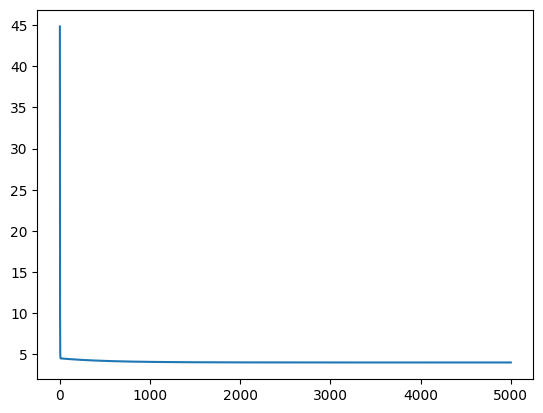

In [17]:
# Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

MSE после градиентного спуска:  4.1903709155046345


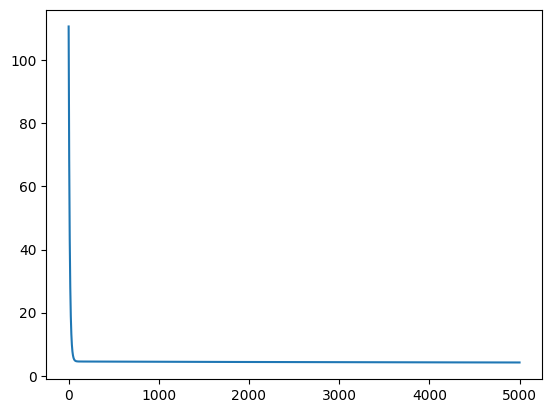

In [18]:
# Запустим цикл градиентного спуска с разными значениями скорости обучения alpha=0.0001, 0.01, 0.1, 1, 10, ...,
# с различной допукстимой точностью epsylon = 0.001, 0.5, 5, с различным максимальным количеством шагов max_steps
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha=0.0001, epsylon=0.01, max_steps=5000)
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
plt.figure()
plt.plot(steps, errors)

Загрузите файл Гиперспектр кукурузы.csv (с помощью pd.read_csv).

1. Вычислите аналитическим путем оценки коэффициентов парной линейной регрессии и постройте ее график.
2. Найдите оценки параметров модели парной лиенйной регрессии с использованием метода градиентного спуска. Постройте график.
3. Оцените качество построенных моделей сравнив на графике обучающую выборку и прогнозы.


In [19]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import Generator as RandomGenerator
from numpy.typing import NDArray
from sklearn.metrics import (
    explained_variance_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [20]:
def evaluate_regression_models(
    predictions: dict[str, NDArray[np.float64]], y: NDArray[np.float64]
) -> pd.DataFrame:
    """Evaluate multiple regression model predictions on the given dataset.

    Args:
        predictions (dict[str, NDArray[np.float64]]): Dictionary where keys are
            model names and values are predicted target arrays corresponding to X.
        y (NDArray[np.float64]): True target values of shape (n_samples,).

    Returns:
        pd.DataFrame: DataFrame with evaluation metrics (MAE, MSE, RMSE, R², EVS) for
            each model. Columns correspond to model names; rows correspond to metrics.
    """
    evaluations = pd.DataFrame(
        columns=predictions.keys(), index=["MAE", "MSE", "RMSE", "R²", "EVS"]
    )

    for name, y_pred in predictions.items():
        metrics = {
            "MAE": mean_absolute_error(y, y_pred),
            "MSE": mean_squared_error(y, y_pred),
            "RMSE": root_mean_squared_error(y, y_pred),
            "R²": r2_score(y, y_pred),
            "EVS": explained_variance_score(y, y_pred),
        }

        evaluations.loc[:, name] = metrics

    return evaluations.astype(float)

In [21]:
gipers = pd.read_csv(r"Гиперспектр кукурузы.csv")
X, y = gipers["wavelength"], gipers["Spectr"]
X, y = X.to_numpy().reshape(-1, 1), y.to_numpy().reshape(-1, 1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [22]:
gipers.head()

,wavelength,Spectr
0,397.32,0.02
1,399.54,0.03
2,401.76,0.03
3,403.98,0.05
4,406.20,0.05


In [23]:
a1 = ((X_train - X_train.mean()) * (y_train - y_train.mean())).mean() / (
    (X_train - X_train.mean()) ** 2
).mean()
a0 = y_train.mean() - a1 * X_train.mean()
print("Модель линейной регрессии: Y^ = ", a0, " + ", a1, "* x")

Модель линейной регрессии: Y^ =  0.28809021255601386  +  0.12007079592936691 * x


MSE после аналитического решения:  0.015822386006818744


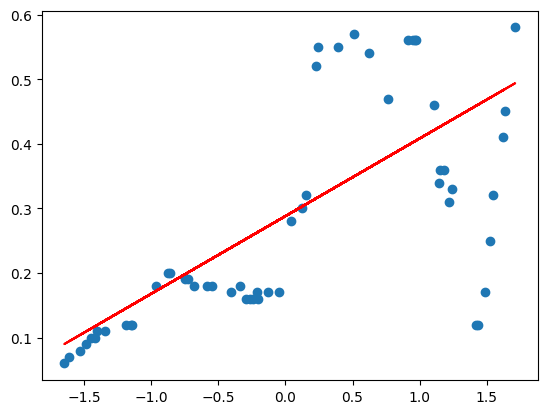

In [24]:
Y_pred = a0 + a1 * X_val
print("MSE после аналитического решения: ", mean_squared_error(y_val, Y_pred))

plt.scatter(X_val, y_val)
plt.plot(X_val, Y_pred, "r")
plt.show()

In [25]:
class MyLinearRegression:
    """Linear Regression using SGD with L1 and L2 regularization.

    This implementation performs optimization using batch size 1 (pure SGD)
    and supports both L1 (Lasso) and L2 (Ridge) regularization to reduce overfitting
    and encourage sparsity.

    Attributes:
        max_epochs (int): Maximum number of training iterations.
        learning_rate (float): Step size for parameter updates.
        tolerance (float): Threshold to determine convergence based on loss change.
        lambda_l1 (float): Coefficient for L1 regularization (Lasso).
        lambda_l2 (float): Coefficient for L2 regularization (Ridge).
        coef_ (NDArray[np.float64] | None): Learned weights for the linear model.
        intercept_ (float): Learned intercept (bias) term.
    """

    def __init__(
        self,
        max_epochs: int = 10000,
        learning_rate: float = 1e-4,
        tolerance: float = 1e-7,
        lambda_l1: float = 0,
        lambda_l2: float = 0,
        random_state: int | None = None,
    ):
        """Initialize the MyLinearRegression model.

        Args:
            max_epochs (int): Number of epochs for SGD. Default is 10,000.
            learning_rate (float): Step size for weight updates. Default is 1e-4.
            tolerance (float): Early stopping threshold for change in loss.
                Default is 1e-7.
            lambda_l1 (float): L1 regularization strength (sparsity). Default is 0.
            lambda_l2 (float): L2 regularization strength (weight decay). Default is 0.
            random_state (int | None): Seed for reproducible training. Default is None.
        """
        self.max_epochs = max_epochs
        self.learning_rate = learning_rate
        self.tolerance = tolerance
        self.lambda_l1 = lambda_l1
        self.lambda_l2 = lambda_l2
        self.rng: RandomGenerator = np.random.default_rng(random_state)

        self.coef_: NDArray[np.float64] | None = None
        self.intercept_: float = 0.0

    def _mse(self, y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
        """Compute mean squared error between true and predicted values.

        Args:
            y_true (NDArray[np.float64]): True target values.
            y_pred (NDArray[np.float64]): Predicted values.

        Returns:
            float: Mean squared error.
        """
        return np.mean((y_pred - y_true) ** 2)

    def _compute_gradients(
        self, x_i: NDArray[np.float64], y_i: float
    ) -> tuple[NDArray[np.float64], float]:
        """Compute gradients of the loss function with respect to weights and bias.

        Args:
            x_i (NDArray[np.float64]): Single input sample of shape (n_features,).
            y_i (float): True target value for the input sample.

        Returns:
            Tuple containing:
                - grad_coef (NDArray[np.float64]): Gradient w.r.t. coefficients.
                - grad_intercept (float): Gradient w.r.t. intercept.
        """
        y_i_pred = self.predict(x_i)
        error_i = y_i_pred - y_i

        grad_coef = 2 * x_i * error_i
        if self.lambda_l1 > 0:
            grad_coef += self.lambda_l1 * np.sign(self.coef_)
        if self.lambda_l2 > 0:
            grad_coef += self.lambda_l2 * self.coef_

        grad_intercept = error_i

        return grad_coef, grad_intercept

    def fit(self, X: NDArray[np.float64], y: NDArray[np.float64]) -> None:
        """Fit the linear regression model to training data using SGD.

        Args:
            X (NDArray[np.float64]): Feature matrix of shape (n_samples, n_features).
            y (NDArray[np.float64]): Target vector of shape (n_samples,).
        """
        m, n_features = X.shape
        self.coef_ = np.zeros(n_features)

        prev_loss = float("inf")

        for _ in range(self.max_epochs):
            indices = self.rng.permutation(m)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            for x_i, y_i in zip(X_shuffled, y_shuffled, strict=False):
                grad_coef, grad_intercept = self._compute_gradients(x_i, y_i)
                self.coef_ -= self.learning_rate * grad_coef
                self.intercept_ -= self.learning_rate * grad_intercept

            y_pred = self.predict(X)
            loss = self._mse(y, y_pred)
            loss += self.lambda_l2 * np.sum(self.coef_**2)
            loss += self.lambda_l1 * np.sum(np.abs(self.coef_))

            if abs(prev_loss - loss) < self.tolerance:
                break

            prev_loss = loss

    def predict(self, X: NDArray[np.float64]) -> NDArray[np.float64]:
        """Predict target values using the trained model.

        Args:
            X (NDArray[np.float64]): Feature matrix of shape (n_samples, n_features).

        Returns:
            NDArray[np.float64]: Predicted values of shape (n_samples,).

        Raises:
            ValueError: If model has not been trained yet.
        """
        if self.coef_ is None:
            raise ValueError("Model is not trained yet. Call `fit` first.")
        return X @ self.coef_ + self.intercept_

In [26]:
my_model = MyLinearRegression(learning_rate=1e-3, tolerance=0, random_state=42)
my_model.fit(X_train, y_train)
print(my_model.coef_, my_model.intercept_)

[0.11964315] [0.28759248]


MSE после градиентного спуска:  0.015788043043371103


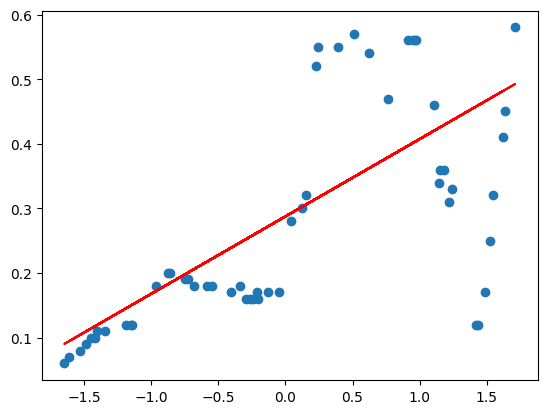

In [27]:
Y_pred = my_model.predict(X_val)
print("MSE после градиентного спуска: ", mean_squared_error(y_val, Y_pred))

plt.scatter(X_val, y_val)
plt.plot(X_val, Y_pred, "r")
plt.show()

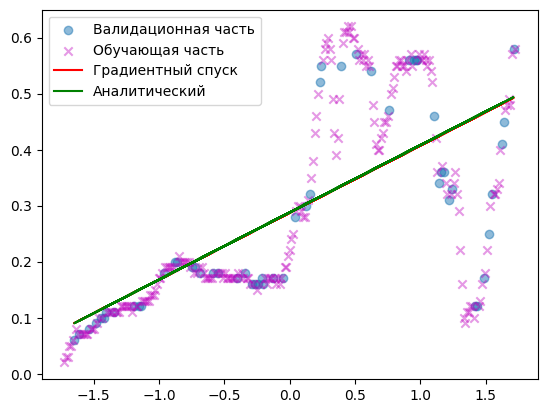

In [28]:
plt.scatter(X_val, y_val, alpha=0.5, label="Валидационная часть")
plt.scatter(X_train, y_train, color="m", marker="x", alpha=0.4, label="Обучающая часть")
plt.plot(X_val, Y_pred, "r", label="Градиентный спуск")
plt.plot(X_val, a0 + a1 * X_val, color="g", label="Аналитический")
plt.legend()
plt.show()

In [29]:
predictions = {
    "analytical": a0 + a1 * X_val,
    "my": Y_pred,
}

evaluate_regression_models(predictions, y_val)

,analytical,my
MAE,0.092370,0.092247
MSE,0.015822,0.015788
RMSE,0.125787,0.125650
R²,0.423952,0.425202
EVS,0.440671,0.441120
